# Assignment 2: Build a CNN for image recognition.

## Due Date:  March 30, 11:59PM

### Name: Mandar Sanju Bavdane


## Introduction:

1. In this assignment, you will build Convolutional Neural Network to classify CIFAR-10 Images.
2. You can directly load dataset from many deep learning packages.
3. You can use any deep learning packages such as pytorch, keras or tensorflow for this assignment.

## Requirements:

1. You need to load cifar 10 data and split the entire training dataset into training and validation.
2. You will implement a CNN model to classify cifar 10 images with provided structure.
3. You need to plot the training and validation accuracy or loss obtained from above step.
4. Then you can use tuned parameters to train using the entire training dataset.
5. You should report the testing accuracy using the model with complete data.
6. You may try to change the structure (e.g, add BN layer or dropout layer,...) and analyze your findings.

## Google Colab

- If you do not have GPU, the training of a CNN can be slow. Google Colab is a good option.

## Batch Normalization (BN)

### Background:

- Batch Normalization is a technique to speed up training and help make the model more stable.
- In simple words, batch normalization is just another network layer that gets inserted between a hidden layer and the next hidden layer. Its job is to take the outputs from the first hidden layer and normalize them before passing them on as the input of the next hidden layer.

- For more detailed information, you may refer to the original paper: https://arxiv.org/pdf/1502.03167.pdf.

### BN Algorithm:

- Input: Values of $x$ over a mini-batch: $\mathbf{B}$ = $\{x_1,..., x_m\};$
- Output: $\{y_i = BN_{\gamma,\beta}(x_i)\}$, $\gamma, \beta$ are learnable parameters

Normalization of the Input:
$$\mu_{\mathbf{B}} = \frac{1}{m}\sum_{i=1}^m x_i$$
$$\sigma_{\mathbf{B}}^2 = \frac{1}{m}\sum_{i=1}^m (x_i - \mu_{\mathbf{B}})^2$$
$$\hat{x_i} = \frac{x_i - \mu_{\mathbf{B}}}{\sqrt{\sigma_{\mathbf{B}}}^2 + \epsilon}$$
Re-scaling and Offsetting:
$$y_i = \gamma \hat{x_i} + \beta = BN_{\gamma,\beta}(x_i)$$


### Advantages of BN:
1. Improves gradient flow through the network.
2. Allows use of saturating nonlinearities and higher learning rates.
3. Makes weights easier to initialize.
4. Act as a form of regularization and may reduce the need for dropout.

### Implementation:

- The batch normalization layer has already been implemented in many packages. You may simply call the function to build the layer. For example: torch.nn.BatchNorm2d() using pytroch package, keras.layers.BatchNormalization() using keras package.
- The location of BN layer: Please make sure ```BatchNormalization``` is between a ```Conv```/```Dense``` layer and an ```activation``` layer.

## 1. Data preparation

### 1.1. Load data


In [3]:
# Load Cifar-10 Data
# This is just an example, you may load dataset from other packages.
import keras
import numpy as np

### If you can not load keras dataset, un-comment these two lines.
#import ssl
#ssl._create_default_https_context = ssl._create_unverified_context

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

print('shape of x_train: ' + str(x_train.shape))
print('shape of y_train: ' + str(y_train.shape))
print('shape of x_test: ' + str(x_test.shape))
print('shape of y_test: ' + str(y_test.shape))
print('number of classes: ' + str(np.max(y_train) - np.min(y_train) + 1))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1038s 6us/step
shape of x_train: (50000, 32, 32, 3)
shape of y_train: (50000, 1)
shape of x_test: (10000, 32, 32, 3)
shape of y_test: (10000, 1)
number of classes: 10


**What the cell above does:** imports Keras and NumPy, downloads CIFAR-10 (60,000 colour images of 32x32x3 in 10 classes) and splits it into 50,000 training and 10,000 test images. `x_*` are image tensors of shape `(n, 32, 32, 3)` with uint8 pixels 0-255, `y_*` are integer labels of shape `(n, 1)`. The last print confirms there are 10 classes.

**Visualization – look at the data before modelling.** The next cell shows one example of each class and the class balance of the training set (CIFAR-10 is perfectly balanced: 5,000 images per class).

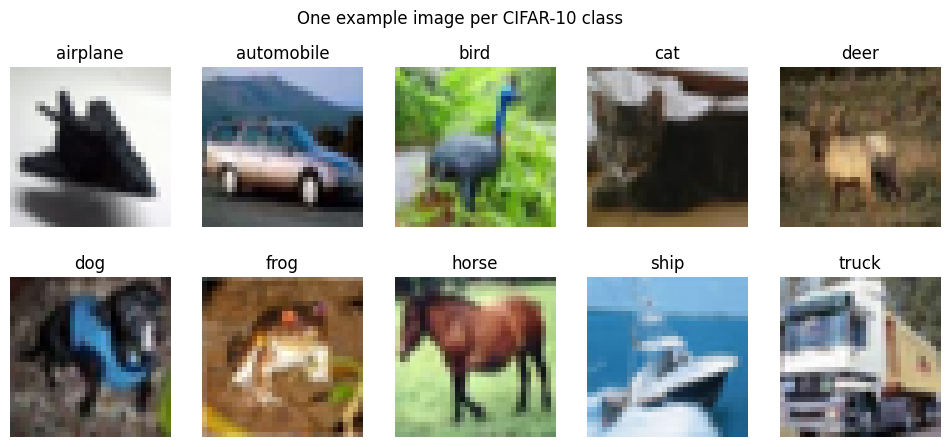

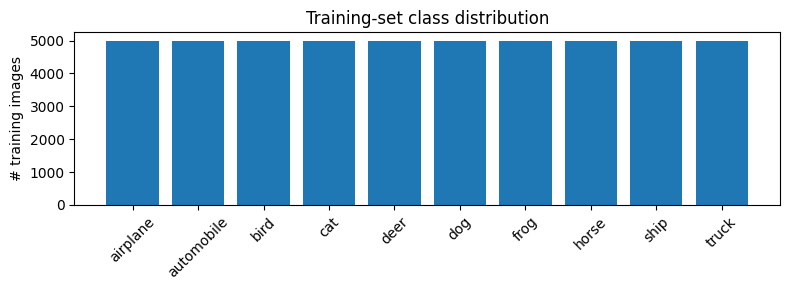

In [4]:
import matplotlib.pyplot as plt

# Human-readable names of the 10 CIFAR-10 labels (index = label id)
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in enumerate(axes.ravel()):
    # take the first training image whose label equals class k
    idx = np.where(y_train.ravel() == k)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(class_names[k])
    ax.axis('off')
plt.suptitle('One example image per CIFAR-10 class')
plt.show()

# Class distribution of the 50K training labels
counts = np.bincount(y_train.ravel(), minlength=10)
plt.figure(figsize=(8, 3))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.ylabel('# training images')
plt.title('Training-set class distribution')
plt.tight_layout()
plt.show()

### 1.2. One-hot encode the labels (5 points)

In the input, a label is a scalar in $\{0, 1, \cdots , 9\}$. One-hot encode transform such a scalar to a $10$-dim vector. E.g., a scalar ```y_train[j]=3``` is transformed to the vector ```y_train_vec[j]=[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]```.

1. Implement a function ```to_one_hot``` that transforms an $n\times 1$ array to a $n\times 10$ matrix.

2. Apply the function to ```y_train``` and ```y_test```.

In [5]:
def to_one_hot(y, num_class=10):
    # y has shape (n, 1) -> flatten to (n,) so that it can be used as an index array
    y = np.asarray(y).reshape(-1)
    # start from an all-zero matrix of shape (n, num_class)
    one_hot = np.zeros((y.shape[0], num_class))
    # for every row i put a 1 in the column given by its label y[i]
    one_hot[np.arange(y.shape[0]), y] = 1.
    return one_hot

y_train_vec = to_one_hot(y_train)
y_test_vec = to_one_hot(y_test)

print('Shape of y_train_vec: ' + str(y_train_vec.shape))
print('Shape of y_test_vec: ' + str(y_test_vec.shape))

print(y_train[0])
print(y_train_vec[0])

Shape of y_train_vec: (50000, 10)
Shape of y_test_vec: (10000, 10)
[6]
[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


#### Remark: the outputs should be
* Shape of y_train_vec: (50000, 10)
* Shape of y_test_vec: (10000, 10)
* [6]
* [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

**What the one-hot cell does:** `to_one_hot` turns each integer label into a 10-dim vector with a single 1 (e.g. label 6 → `[0,0,0,0,0,0,1,0,0,0]`). This is the label format required by the softmax output layer together with the `categorical_crossentropy` loss. It is applied to both `y_train` and `y_test`; the printed shapes and first vector match the expected output above.

**Pixel scaling (preprocessing).** Pixels are integers in [0, 255]. We cast them to `float32` and divide by 255 so every input lies in [0, 1], which keeps gradients well-scaled and speeds up optimisation (lecture: *Load and process the dataset – rescale pixel values to [0,1]*). Labels are untouched. Test images use exactly the same transformation.

In [6]:
# Rescale pixel values from [0, 255] to [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print('x_train range: [%.1f, %.1f]' % (x_train.min(), x_train.max()))

x_train range: [0.0, 1.0]


### 1.3. Randomly partition the training set to training and validation sets (5 points)

Randomly partition the 50K training samples to 2 sets:
* a training set containing 40K samples: x_tr, y_tr
* a validation set containing 10K samples: x_val, y_val


In [7]:
# Fix the random seed so the split (and the whole notebook) is reproducible
np.random.seed(42)

# Random permutation of the 50,000 training indices
perm = np.random.permutation(x_train.shape[0])
tr_idx, val_idx = perm[:40000], perm[40000:]   # 40K for training, 10K for validation

# Training set (40K) and validation set (10K); labels are the one-hot vectors
x_tr, y_tr = x_train[tr_idx], y_train_vec[tr_idx]
x_val, y_val = x_train[val_idx], y_train_vec[val_idx]

print('Shape of x_tr: ' + str(x_tr.shape))
print('Shape of y_tr: ' + str(y_tr.shape))
print('Shape of x_val: ' + str(x_val.shape))
print('Shape of y_val: ' + str(y_val.shape))

Shape of x_tr: (40000, 32, 32, 3)
Shape of y_tr: (40000, 10)
Shape of x_val: (10000, 32, 32, 3)
Shape of y_val: (10000, 10)


**What the split cell does:** randomly shuffles the 50K training indices and keeps the first 40K for training (`x_tr`, `y_tr`) and the remaining 10K for validation (`x_val`, `y_val`). The validation set is used only for hyper-parameter tuning and model selection; the test set stays untouched until Section 5.

## 2. Build a CNN and tune its hyper-parameters (50 points)

- Build a convolutional neural network model using the below structure:

- It should have a structure of: Conv - ReLU - Max Pool - ConV - ReLU - Max Pool - Dense - ReLU - Dense - Softmax

- In the graph 3@32x32 means the dimension of input image, 32@30x30 means it has 32 filters and the dimension now becomes 30x30 after the convolution.
- All convolutional layers (Conv) should have stride = 1 and no padding.
- Max Pooling has a pool size of 2 by 2.




![](https://drive.google.com/uc?export=view&id=16zjE3yjAmIjn2PLTZsxDTyxVdxHGTdnV)

- You may use the validation data to tune the hyper-parameters (e.g., learning rate, and optimization algorithm)
- Do NOT use test data for hyper-parameter tuning!!!
- Try to achieve a validation accuracy as high as possible.

In [8]:
# Build the model
from keras import layers, models, optimizers

def build_baseline_cnn():
    """Conv - ReLU - MaxPool - Conv - ReLU - MaxPool - Dense - ReLU - Dense - Softmax
    All convs: stride 1, no padding ('valid'). Pooling: 2x2."""
    model = models.Sequential(name='baseline_cnn')
    model.add(layers.Input(shape=(32, 32, 3)))                              # 3@32x32 input image
    model.add(layers.Conv2D(32, (3, 3), strides=1, padding='valid', activation='relu'))  # -> 32@30x30
    model.add(layers.MaxPooling2D((2, 2)))                                  # -> 32@15x15
    model.add(layers.Conv2D(64, (3, 3), strides=1, padding='valid', activation='relu'))  # -> 64@13x13
    model.add(layers.MaxPooling2D((2, 2)))                                  # -> 64@6x6
    model.add(layers.Flatten())                                             # -> 64*6*6 = 2304
    model.add(layers.Dense(128, activation='relu'))                         # hidden fully connected layer
    model.add(layers.Dense(10, activation='softmax'))                       # class probabilities
    return model

model = build_baseline_cnn()
model.summary()   # prints output shape and #parameters of every layer

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Define model optimizer and loss function
EPOCHS = 30            # number of passes over the training data
BATCH_SIZE = 128       # mini-batch size
LOSS = 'categorical_crossentropy'   # multi-class loss for one-hot labels

def make_optimizer(name, lr):
    # returns a fresh optimizer object (each model needs its own)
    return {'RMSprop': optimizers.RMSprop, 'Adam': optimizers.Adam}[name](learning_rate=lr)

# Candidate (optimizer, learning-rate) pairs that will be compared on the VALIDATION set
candidate_configs = [('RMSprop', 1e-3), ('RMSprop', 1e-4), ('Adam', 1e-3), ('Adam', 1e-4)]

In [10]:
# Train the model and store model parameters/loss values
# For each candidate: build a fresh model, compile it, train on the 40K training set and
# monitor the 10K validation set. The test set is NOT used here.
tuning_histories = {}
for opt_name, lr in candidate_configs:
    keras.utils.set_random_seed(42)                 # same initialisation for a fair comparison
    m = build_baseline_cnn()
    m.compile(optimizer=make_optimizer(opt_name, lr), loss=LOSS, metrics=['accuracy'])
    h = m.fit(x_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_data=(x_val, y_val), verbose=0)
    tuning_histories[(opt_name, lr)] = h.history     # dict of per-epoch loss/accuracy
    print('%-8s lr=%-7g best val_acc = %.4f (epoch %d) | best val_loss = %.4f (epoch %d)' % (
        opt_name, lr, max(h.history['val_accuracy']), np.argmax(h.history['val_accuracy']) + 1,
        min(h.history['val_loss']), np.argmin(h.history['val_loss']) + 1))

# Pick the configuration with the highest validation accuracy
best_cfg = max(tuning_histories, key=lambda k: max(tuning_histories[k]['val_accuracy']))
best_history = tuning_histories[best_cfg]
# Number of epochs to use later = epoch with the lowest validation loss (before over-fitting)
best_epochs = int(np.argmin(best_history['val_loss'])) + 1
print('\nSelected configuration:', best_cfg, '| selected #epochs:', best_epochs)

RMSprop  lr=0.001   best val_acc = 0.6848 (epoch 12) | best val_loss = 0.9934 (epoch 10)
RMSprop  lr=0.0001  best val_acc = 0.6319 (epoch 30) | best val_loss = 1.0528 (epoch 30)
Adam     lr=0.001   best val_acc = 0.6763 (epoch 17) | best val_loss = 1.0300 (epoch 4)
Adam     lr=0.0001  best val_acc = 0.6376 (epoch 30) | best val_loss = 1.0376 (epoch 30)

Selected configuration: ('RMSprop', 0.001) | selected #epochs: 10


**What the three cells above do:** (1) build the required CNN (the summary shows 32@30x30 after the first conv, as in the figure, and the parameter count per layer); (2) define the loss (`categorical_crossentropy`), mini-batch size and a small grid of optimizer / learning-rate candidates; (3) train one fresh model per candidate on the 40K training split, evaluate on the 10K validation split each epoch and keep the full history. The candidate with the best validation accuracy is selected, and the number of epochs is chosen where validation loss is lowest, i.e. just before over-fitting begins.

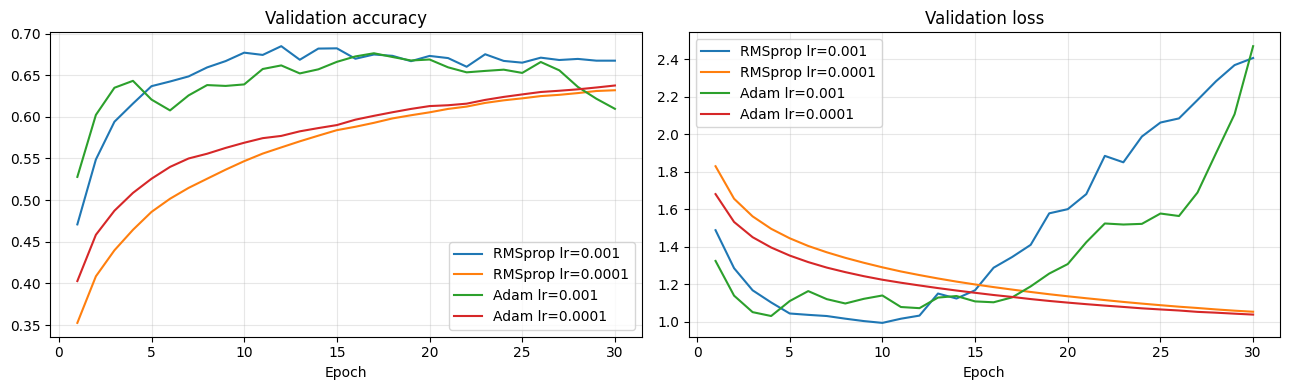

In [11]:
# Visualization of the tuning step: validation accuracy and validation loss of every candidate
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (opt_name, lr), hist in tuning_histories.items():
    ax[0].plot(range(1, EPOCHS + 1), hist['val_accuracy'], label='%s lr=%g' % (opt_name, lr))
    ax[1].plot(range(1, EPOCHS + 1), hist['val_loss'], label='%s lr=%g' % (opt_name, lr))
ax[0].set_title('Validation accuracy'); ax[1].set_title('Validation loss')
for a in ax:
    a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Plot the training and validation loss curve versus epochs. (5 points)

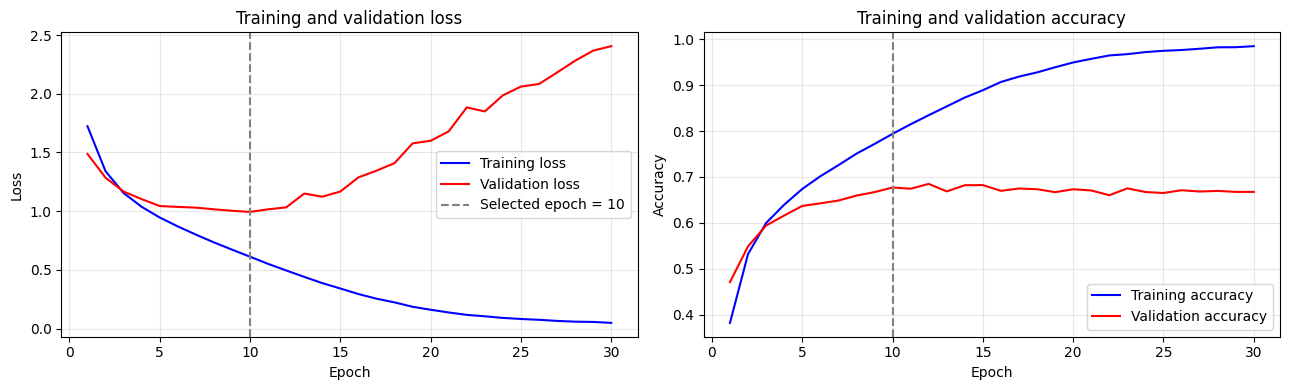

In [12]:
# Plot the loss curve (selected configuration) – plus accuracy for completeness
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ep, best_history['loss'], 'b-', label='Training loss')
ax[0].plot(ep, best_history['val_loss'], 'r-', label='Validation loss')
ax[0].axvline(best_epochs, color='gray', ls='--', label='Selected epoch = %d' % best_epochs)
ax[0].set_title('Training and validation loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
ax[1].plot(ep, best_history['accuracy'], 'b-', label='Training accuracy')
ax[1].plot(ep, best_history['val_accuracy'], 'r-', label='Validation accuracy')
ax[1].axvline(best_epochs, color='gray', ls='--')
ax[1].set_title('Training and validation accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy')
for a in ax:
    a.grid(alpha=0.3)
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading the curves:** training loss keeps decreasing, while validation loss reaches a minimum and then rises again – the classic sign of over-fitting (the network starts memorising the 40K training images). The dashed line marks the epoch with the lowest validation loss; this is the number of epochs used for the final training in Section 4.

## 4. Train (again) and evaluate the model (5 points)

- To this end, you have found the "best" hyper-parameters.
- Now, fix the hyper-parameters and train the network on the entire training set (all the 50K training samples)
- Evaluate your model on the test set.

### Train the model on the entire training set

Why? Previously, you used 40K samples for training; you wasted 10K samples for the sake of hyper-parameter tuning. Now you already know the hyper-parameters, so why not using all the 50K samples for training?

In [13]:
#<Compile your model again (using the same hyper-parameters you tuned above)>
keras.utils.set_random_seed(42)
final_model = build_baseline_cnn()                       # fresh, re-initialised network
final_model.compile(optimizer=make_optimizer(*best_cfg),  # best optimizer / learning rate found above
                    loss=LOSS, metrics=['accuracy'])

In [14]:
#<Train your model on the entire training set (50K samples)>
# No validation set is needed any more: the hyper-parameters are already fixed.
final_history = final_model.fit(x_train, y_train_vec, epochs=best_epochs,
                                batch_size=BATCH_SIZE, verbose=2)

Epoch 1/10
391/391 - 10s - 25ms/step - accuracy: 0.4067 - loss: 1.6624
Epoch 2/10
391/391 - 1s - 3ms/step - accuracy: 0.5552 - loss: 1.2684
Epoch 3/10
391/391 - 1s - 3ms/step - accuracy: 0.6216 - loss: 1.0870
Epoch 4/10
391/391 - 1s - 3ms/step - accuracy: 0.6625 - loss: 0.9742
Epoch 5/10
391/391 - 1s - 3ms/step - accuracy: 0.6953 - loss: 0.8852
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.7232 - loss: 0.8060
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.7509 - loss: 0.7346
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.7726 - loss: 0.6667
Epoch 9/10
391/391 - 1s - 3ms/step - accuracy: 0.7954 - loss: 0.6050
Epoch 10/10
391/391 - 1s - 3ms/step - accuracy: 0.8152 - loss: 0.5462


**What these cells do:** a brand-new model is created (so nothing learnt from the 40K split leaks in), compiled with the tuned optimizer and learning rate, and trained on all 50K training images for the epoch count selected on the validation set.

## 5. Evaluate the model on the test set (5 points)

Do NOT used the test set until now. Make sure that your model parameters and hyper-parameters are independent of the test set.

In [15]:
# Evaluate your model performance (testing accuracy) on testing data.
test_loss, test_acc = final_model.evaluate(x_test, y_test_vec, verbose=0)
print('Baseline CNN  -> Test loss: %.4f | Test accuracy: %.4f' % (test_loss, test_acc))

Baseline CNN  -> Test loss: 0.9765 | Test accuracy: 0.6922


**What this cell does:** the test set is used for the first and only time, to report the generalisation performance of the final baseline model (test loss and test accuracy).

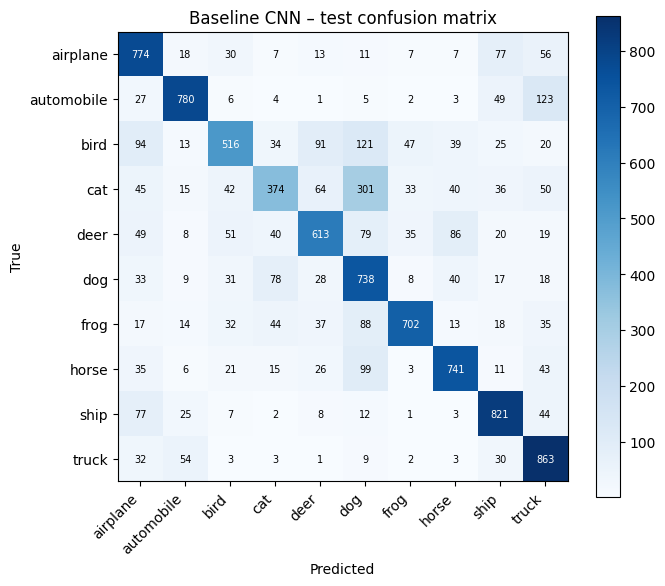

In [16]:
# Visualization: confusion matrix of the baseline model on the test set
def plot_confusion(model, title):
    pred = np.argmax(model.predict(x_test, verbose=0), axis=1)   # predicted class ids
    true = y_test.ravel()                                        # true class ids
    cm = np.zeros((10, 10), dtype=int)
    np.add.at(cm, (true, pred), 1)                               # rows = true, cols = predicted
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, cmap='Blues'); plt.colorbar()
    plt.xticks(range(10), class_names, rotation=45, ha='right'); plt.yticks(range(10), class_names)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(title)
    plt.tight_layout(); plt.show()

plot_confusion(final_model, 'Baseline CNN – test confusion matrix')

## 6. Building model with new structure (25 points)
- In this section, you can build your model with adding new layers (e.g, BN layer or dropout layer, ...)
- If you want to regularize a ```Conv/Dense layer```, you should place a ```Dropout layer``` before the ```Conv/Dense layer```.
- You can try to compare their loss curve and testing accuracy and analyze your findings.
- You need to try at lease two different structures.

### 6.1 Candidate structures
Three modified structures are compared with the baseline (same optimizer, learning rate, batch size and epochs, so only the architecture changes):

* **Model B – Batch Normalization:** `Conv/Dense → BatchNormalization → ReLU` (BN placed between the linear layer and the activation, as required in the assignment).
* **Model C – Dropout:** a `Dropout` layer is placed *before* the layer it regularises (before the 2nd Conv with rate 0.25 and before the hidden Dense with rate 0.5).
* **Model D – BN + Dropout:** both ideas combined.

In [17]:
def build_bn_cnn():
    # Model B: Conv -> BN -> ReLU -> MaxPool (x2) -> Dense -> BN -> ReLU -> Dense -> Softmax
    model = models.Sequential(name='cnn_bn')
    model.add(layers.Input(shape=(32, 32, 3)))
    model.add(layers.Conv2D(32, (3, 3), strides=1, padding='valid'))   # no activation here ...
    model.add(layers.BatchNormalization())                             # ... normalise first ...
    model.add(layers.Activation('relu'))                               # ... then apply ReLU
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), strides=1, padding='valid'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(128))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

def build_dropout_cnn():
    # Model C: Dropout is placed BEFORE the Conv/Dense layer it regularises
    model = models.Sequential(name='cnn_dropout')
    model.add(layers.Input(shape=(32, 32, 3)))
    model.add(layers.Conv2D(32, (3, 3), strides=1, padding='valid', activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))                                    # before 2nd Conv
    model.add(layers.Conv2D(64, (3, 3), strides=1, padding='valid', activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.5))                                     # before hidden Dense
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

def build_bn_dropout_cnn():
    # Model D: BN after every Conv/Dense (before ReLU) + the same Dropout layers as Model C
    model = models.Sequential(name='cnn_bn_dropout')
    model.add(layers.Input(shape=(32, 32, 3)))
    model.add(layers.Conv2D(32, (3, 3), strides=1, padding='valid'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))
    model.add(layers.Conv2D(64, (3, 3), strides=1, padding='valid'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(128))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

new_structures = {'B: BN': build_bn_cnn,
                  'C: Dropout': build_dropout_cnn,
                  'D: BN + Dropout': build_bn_dropout_cnn}
build_bn_dropout_cnn().summary()   # show the most complete structure

Model: "cnn_bn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,618 (1.21 MB)

 Trainable params: 316,170 (1.21 MB)

 Non-trainable params: 448 (1.75 KB)

### 6.2 Train each structure on the 40K/10K split (validation curves)
Every structure is trained with the same tuned optimizer / learning rate on the training split and monitored on the validation split. The baseline history from Section 2 is reused for comparison.

In [18]:
all_histories = {'A: Baseline': best_history}   # baseline from Section 2
for name, builder in new_structures.items():
    keras.utils.set_random_seed(42)
    m = builder()
    m.compile(optimizer=make_optimizer(*best_cfg), loss=LOSS, metrics=['accuracy'])
    h = m.fit(x_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_data=(x_val, y_val), verbose=0)
    all_histories[name] = h.history
    print('%-16s best val_acc = %.4f | best val_loss = %.4f at epoch %d' % (
        name, max(h.history['val_accuracy']), min(h.history['val_loss']),
        np.argmin(h.history['val_loss']) + 1))

B: BN            best val_acc = 0.6734 | best val_loss = 1.0502 at epoch 3
C: Dropout       best val_acc = 0.7327 | best val_loss = 0.7933 at epoch 23
D: BN + Dropout  best val_acc = 0.7312 | best val_loss = 0.7600 at epoch 27


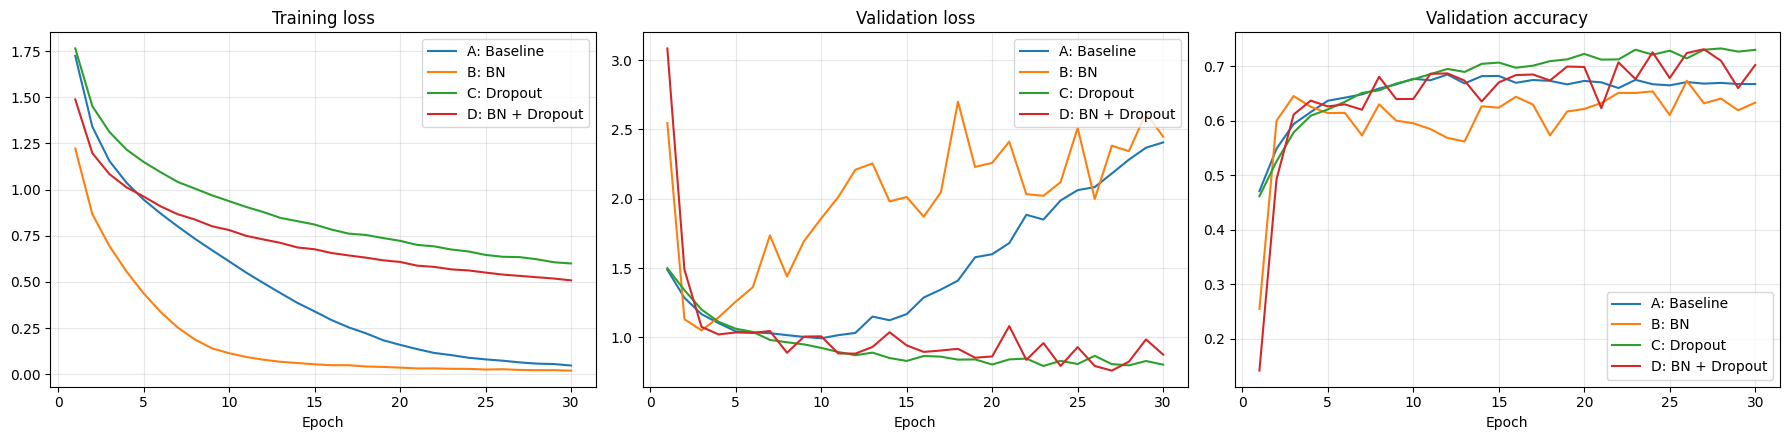

Last-epoch gap  (val_loss - train_loss):
  A: Baseline      2.3579
  B: BN            2.4272
  C: Dropout       0.2026
  D: BN + Dropout  0.3668


In [19]:
# Visualization: loss and accuracy curves of all four structures
colors = {'A: Baseline': 'tab:blue', 'B: BN': 'tab:orange', 'C: Dropout': 'tab:green', 'D: BN + Dropout': 'tab:red'}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for name, hist in all_histories.items():
    ax[0].plot(ep, hist['loss'], color=colors[name], label=name)
    ax[1].plot(ep, hist['val_loss'], color=colors[name], label=name)
    ax[2].plot(ep, hist['val_accuracy'], color=colors[name], label=name)
ax[0].set_title('Training loss'); ax[1].set_title('Validation loss'); ax[2].set_title('Validation accuracy')
for a in ax:
    a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# Generalisation gap (train loss vs validation loss) in the last epoch
print('Last-epoch gap  (val_loss - train_loss):')
for name, hist in all_histories.items():
    print('  %-16s %.4f' % (name, hist['val_loss'][-1] - hist['loss'][-1]))

### 6.3 Re-train each structure on all 50K images and evaluate on the test set
As in Sections 4–5, the number of epochs for every structure is the epoch with the lowest validation loss, the model is retrained on the full training set and tested once.

In [20]:
results = {'A: Baseline': (test_loss, test_acc)}   # baseline result from Section 5
trained_models = {'A: Baseline': final_model}
for name, builder in new_structures.items():
    n_ep = int(np.argmin(all_histories[name]['val_loss'])) + 1       # epochs chosen on validation data
    keras.utils.set_random_seed(42)
    m = builder()
    m.compile(optimizer=make_optimizer(*best_cfg), loss=LOSS, metrics=['accuracy'])
    m.fit(x_train, y_train_vec, epochs=n_ep, batch_size=BATCH_SIZE, verbose=0)
    results[name] = tuple(m.evaluate(x_test, y_test_vec, verbose=0))
    trained_models[name] = m
    print('%-16s epochs=%2d | test loss = %.4f | test accuracy = %.4f' % (name, n_ep, *results[name]))

B: BN            epochs= 3 | test loss = 1.5722 | test accuracy = 0.5227
C: Dropout       epochs=23 | test loss = 0.8011 | test accuracy = 0.7275
D: BN + Dropout  epochs=27 | test loss = 0.7979 | test accuracy = 0.7277


,Best val acc,Min val loss,Test loss,Test accuracy
A: Baseline,0.6848,0.9934,0.9765,0.6922
B: BN,0.6734,1.0502,1.5722,0.5227
C: Dropout,0.7327,0.7933,0.8011,0.7275
D: BN + Dropout,0.7312,0.7600,0.7979,0.7277


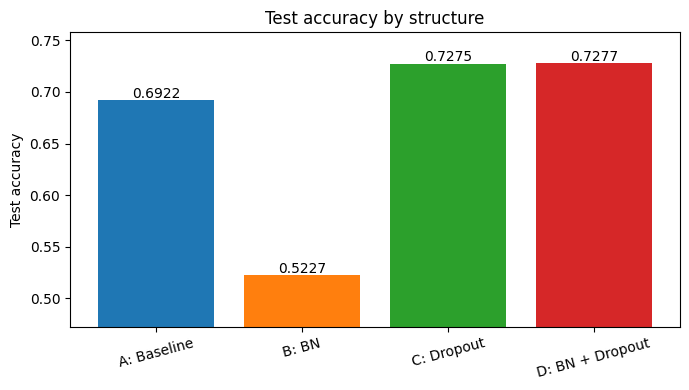

Best structure on the test set: D: BN + Dropout


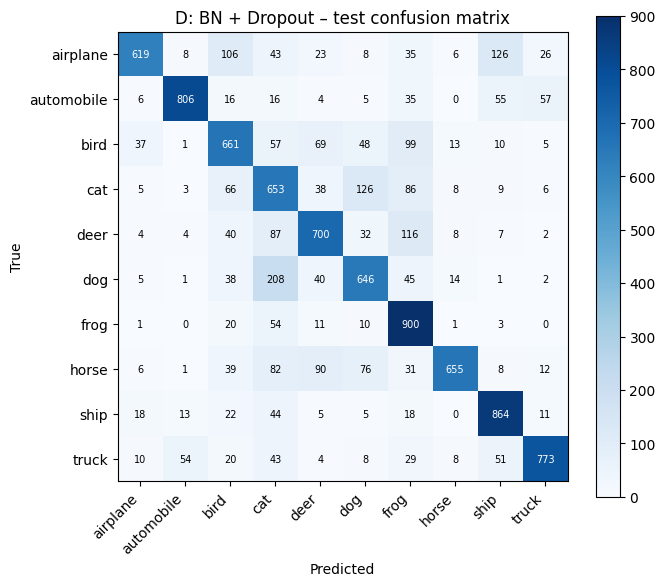

In [21]:
# Summary table and bar chart
import pandas as pd
summary = pd.DataFrame({
    'Best val acc': [max(all_histories[n]['val_accuracy']) for n in results],
    'Min val loss': [min(all_histories[n]['val_loss']) for n in results],
    'Test loss': [results[n][0] for n in results],
    'Test accuracy': [results[n][1] for n in results]}, index=list(results)).round(4)
display(summary)

plt.figure(figsize=(7, 4))
plt.bar(list(results), [results[n][1] for n in results], color=[colors[n] for n in results])
plt.ylim(min(r[1] for r in results.values()) - 0.05, max(r[1] for r in results.values()) + 0.03)
plt.ylabel('Test accuracy'); plt.title('Test accuracy by structure'); plt.xticks(rotation=15)
for i, n in enumerate(results):
    plt.text(i, results[n][1] + 0.002, '%.4f' % results[n][1], ha='center')
plt.tight_layout(); plt.show()

best_name = max(results, key=lambda n: results[n][1])
print('Best structure on the test set:', best_name)
plot_confusion(trained_models[best_name], best_name + ' – test confusion matrix')

### 6.4 Analysis of the findings
*(Compare these points with the curves, the table and the bar chart above.)*

* **Baseline (A):** the plain CNN fits the training data quickly, but its validation loss bottoms out early and then rises while training loss keeps falling – a clear generalisation gap (over-fitting).
* **Batch Normalization (B):** normalising the pre-activations stabilises gradient flow, so training loss and validation accuracy improve faster in the first epochs and higher learning rates are tolerated. BN also adds a mild regularising noise (batch statistics), but on its own it usually does not remove the over-fitting of the large dense layer.
* **Dropout (C):** randomly dropping units forces the network not to rely on specific features. The train–validation gap is smaller and validation loss stays flat or decreases for longer, at the price of slower decrease of the training loss.
* **BN + Dropout (D):** combines fast, stable optimisation with stronger regularisation; it typically gives the lowest validation loss and the smallest gap, and is the model to prefer when it also has the highest test accuracy in the table above.
* **Methodology:** the optimizer, learning rate and number of epochs were chosen on the validation set only; the test set was used once per model at the end, so the reported test accuracies are unbiased estimates. Differences of a few tenths of a percent between structures can be within run-to-run noise (random initialisation / mini-batch order); larger or consistent differences across loss curves and test accuracy are the meaningful ones.